# Held-out feature and error diagnostics

In [1]:
from pathlib import Path
import sys
import duckdb, pandas as pd, matplotlib.pyplot as plt
root=next(path for path in [Path.cwd(), *Path.cwd().parents] if (path/'config/default.json').exists())
sys.path.insert(0,str(root))
output=root/'artifacts'
figures=root/'reports/figures'
db=duckdb.connect(str(output/'operations.duckdb'),read_only=True,config={'threads':2})
def read(name):
    return pd.read_csv(output/f'{name}.csv')

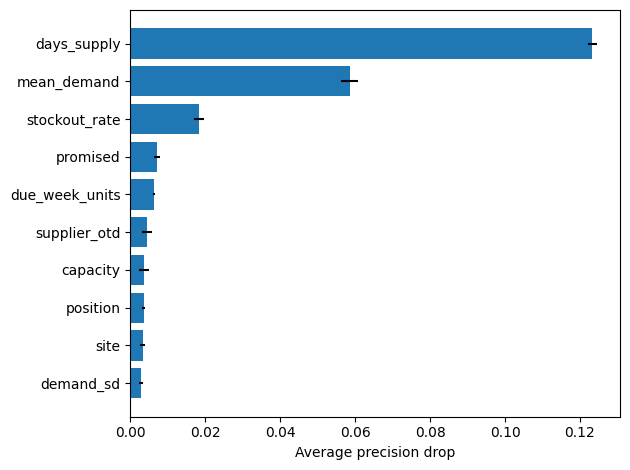

,dimension,segment,observations,prevalence,pr_auc,recall,fp,fn
0,site,0,14400,0.391875,0.732625,0.696615,1926,1712
1,site,1,14400,0.707361,0.965574,0.974573,1314,259
2,site,2,14400,0.649653,0.955424,0.956387,1626,408
3,site,3,14400,0.550417,0.887977,0.892380,2031,853
4,site,4,14400,0.624514,0.922929,0.936061,1942,575
5,category,0,14400,0.638611,0.946960,0.930187,1583,642
6,category,1,14400,0.591319,0.894310,0.902995,1930,826
7,category,2,14400,0.608403,0.933534,0.928090,1905,630
8,category,3,14400,0.620417,0.912948,0.885270,1907,1025
9,category,4,14400,0.465069,0.924115,0.897865,1514,684


In [2]:
imp=read('importance').head(10).sort_values('ap_drop')
plt.barh(imp.feature,imp.ap_drop,xerr=imp.sd)
plt.xlabel('Average precision drop')
plt.tight_layout()
plt.savefig(figures/'importance.png',dpi=130)
plt.show()
display(read('segments')[['dimension','segment','observations','prevalence','pr_auc','recall','fp','fn']])

Permutation estimates capture model reliance in a held-out sample. Correlated coverage features can substitute for one another. Subgroup errors may reflect policy and prevalence shifts.